# 앙상블 모델 추가 실습 과제

# Task
앙상블 모델 실습을 위한 신용카드 거래 데이터(credit_card.csv)의 탐색적 데이터 분석(EDA)을 수행합니다. 데이터 로드 및 결측치/타입 점검, 클래스 불균형 및 주요 피처 분포 분석, 시각화를 통한 데이터 특성 파악을 진행합니다.

## 데이터 로드 및 기본 정보 확인

### Subtask:
credit_card.csv 데이터를 로드하고 기본 구조, 결측치, 데이터 타입 및 기초 통계량을 점검합니다.


**Reasoning**:
credit_card.csv 파일 경로를 찾아서 데이터를 pandas DataFrame으로 로드하고 기본 정보(shape, info, 결측치, 기초 통계량)를 확인합니다.



In [1]:
import os
import glob
import pandas as pd
import numpy as np

# 파일 경로 탐색
candidate_files = glob.glob('**/credit_card*.csv', recursive=True) + glob.glob('**/creditcard*.csv', recursive=True) + glob.glob('*.csv')
print("Found files:", candidate_files)

file_path = None
for f in candidate_files:
    if 'credit' in f.lower():
        file_path = f
        break

if file_path is None and len(candidate_files) > 0:
    file_path = candidate_files[0]

print(f"Loading dataset from: {file_path}")
df = pd.read_csv(file_path)

print(f"\n--- Data Shape ---\n{df.shape}")
print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Data Info ---")
df.info()

print("\n--- Missing Values ---")
print(df.isnull().sum()[df.isnull().sum() > 0])
if df.isnull().sum().sum() == 0:
    print("No missing values found.")

print("\n--- Descriptive Statistics ---")
display(df.describe())

Found files: ['credit_card.csv', 'summary_by_category.csv', 'preprocessing_diagnosis.csv', 'customer_orders.csv', 'boston_train.csv', 'credit_card.csv', 'mushroom.csv', 'titanic_train.csv', 'rejected_data.csv', 'boston_test.csv', 'titanic_test.csv', 'iris.csv', 'featured_customer_orders.csv', 'cleaned_data.csv', 'summary_by_month.csv', 'Breast Cancer.csv']
Loading dataset from: credit_card.csv

--- Data Shape ---
(30000, 24)

--- First 5 Rows ---


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0



--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   LIMIT_BAL                   30000 non-null  int64
 1   SEX                         30000 non-null  int64
 2   EDUCATION                   30000 non-null  int64
 3   MARRIAGE                    30000 non-null  int64
 4   AGE                         30000 non-null  int64
 5   PAY_0                       30000 non-null  int64
 6   PAY_2                       30000 non-null  int64
 7   PAY_3                       30000 non-null  int64
 8   PAY_4                       30000 non-null  int64
 9   PAY_5                       30000 non-null  int64
 10  PAY_6                       30000 non-null  int64
 11  BILL_AMT1                   30000 non-null  int64
 12  BILL_AMT2                   30000 non-null  int64
 13  BILL_AMT3                   30000 non-null

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,-0.266200,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,1.133187,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


## 타깃 변수 및 주요 피처 분포 분석

### Subtask:
타깃 변수(연체 여부)의 클래스 불균형 정도와 범주형/수치형 주요 피처의 타깃별 분포 및 통계적 특성을 분석합니다.


**Reasoning**:
타깃 변수의 비율을 확인하고, 인구통계 범주형 변수별 연체율 및 주요 수치형 변수의 타깃별 평균/중앙값을 집계하여 출력합니다.



In [3]:
# 1. 타깃 변수(default payment next month) 분포 분석
target_col = 'default payment next month'
target_counts = df[target_col].value_counts()
target_ratios = df[target_col].value_counts(normalize=True) * 100
target_summary = pd.DataFrame({'Count': target_counts, 'Percentage (%)': target_ratios})
print('=== 타깃 변수 클래스 분포 ===')
display(target_summary)

# 2. 범주형 변수(SEX, EDUCATION, MARRIAGE)별 연체율 분석
cat_cols = ['SEX', 'EDUCATION', 'MARRIAGE']
print('\n=== 범주형 변수별 연체율 ===')
for col in cat_cols:
    col_summary = df.groupby(col)[target_col].agg(['count', 'mean']).rename(columns={'count': '총 인원', 'mean': '연체율'})
    col_summary['연체율 (%)'] = col_summary['연체율'] * 100
    print(f'\n-- [{col}] 별 연체율 --')
    display(col_summary)

# 3. 주요 수치형 변수의 연체 유무별 평균 및 중앙값 비교
num_cols = ['LIMIT_BAL', 'AGE', 'PAY_0', 'BILL_AMT1', 'PAY_AMT1']
print('\n=== 타깃별 주요 수치형 변수 평균 및 중앙값 비교 ===')
num_comparison = df.groupby(target_col)[num_cols].agg(['mean', 'median'])
display(num_comparison)

=== 타깃 변수 클래스 분포 ===


,Count,Percentage (%)
default payment next month,,
0,23364,77.88
1,6636,22.12



=== 범주형 변수별 연체율 ===

-- [SEX] 별 연체율 --


,총 인원,연체율,연체율 (%)
SEX,,,
1,11888,0.241672,24.167227
2,18112,0.207763,20.776281



-- [EDUCATION] 별 연체율 --


,총 인원,연체율,연체율 (%)
EDUCATION,,,
0,14,0.000000,0.000000
1,10585,0.192348,19.234766
2,14030,0.237349,23.734854
3,4917,0.251576,25.157616
4,123,0.056911,5.691057
5,280,0.064286,6.428571
6,51,0.156863,15.686275



-- [MARRIAGE] 별 연체율 --


,총 인원,연체율,연체율 (%)
MARRIAGE,,,
0,54,0.092593,9.259259
1,13659,0.234717,23.471704
2,15964,0.209283,20.928339
3,323,0.260062,26.006192



=== 타깃별 주요 수치형 변수 평균 및 중앙값 비교 ===


LIMIT_BAL                  AGE         \
                                     mean    median       mean median   
default payment next month                                              
0                           178099.726074  150000.0  35.417266   34.0   
1                           130109.656420   90000.0  35.725738   34.0   

                               PAY_0            BILL_AMT1           \
                                mean median          mean   median   
default payment next month                                           
0                          -0.211222    0.0  51994.227273  23119.5   
1                           0.668174    1.0  48509.162297  20185.0   

                               PAY_AMT1          
                                   mean  median  
default payment next month                       
0                           6307.337357  2459.5  
1                           3397.044153  1636.0

# Task
신용카드 고객 연체 예측 데이터(`credit_card.csv`)를 활용하여 데이터 전처리 및 학습/테스트 데이터셋 분할을 수행하고, Random Forest, Gradient Boosting 등 주요 앙상블 분류 모델을 학습시킵니다. 이후 테스트 데이터셋에 대해 Accuracy, Precision, Recall, F1-score, ROC-AUC 등 다양한 평가지표를 계산하여 비교하고, ROC 곡선 및 혼동 행렬, 피처 중요도 시각화를 통해 최적의 앙상블 모델을 선정하고 인사이트를 도출합니다.

## 데이터 전처리 및 데이터 분할

### Subtask:
credit_card.csv 데이터를 바탕으로 피처(X)와 타깃(y)을 분리하고, 학습용/테스트용 데이터셋으로 분할합니다.


**Reasoning**:
X와 y를 분리하고 train_test_split을 사용하여 8:2로 계층화 분할을 수행합니다.



In [4]:
from sklearn.model_selection import train_test_split

target_col = 'default payment next month'
X = df.drop(columns=[target_col])
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}, y_test shape: {y_test.shape}")
print("\n--- Train target ratio ---")
print(y_train.value_counts(normalize=True).to_dict())
print("--- Test target ratio ---")
print(y_test.value_counts(normalize=True).to_dict())

X_train shape: (24000, 23), y_train shape: (24000,)
X_test shape: (6000, 23), y_test shape: (6000,)

--- Train target ratio ---
{0: 0.7787916666666667, 1: 0.22120833333333334}
--- Test target ratio ---
{0: 0.7788333333333334, 1: 0.22116666666666668}


## 앙상블 모델 학습

### Subtask:
Random Forest, Gradient Boosting, LightGBM 등 주요 앙상블 분류 모델을 생성하고 학습 데이터(X_train, y_train)에 피팅합니다.


**Reasoning**:
앙상블 모델인 RandomForest, GradientBoosting, AdaBoost, LightGBM을 정의하고 X_train, y_train으로 학습을 진행합니다.



In [5]:
import time
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
import lightgbm as lgb

models = {
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=42),
    'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=42),
    'LightGBM': lgb.LGBMClassifier(n_estimators=100, learning_rate=0.1, random_state=42, verbose=-1)
}

trained_models = {}
training_times = {}

for name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)
    elapsed_time = time.time() - start_time
    trained_models[name] = model
    training_times[name] = elapsed_time
    print(f"{name} 학습 완료 (소요 시간: {elapsed_time:.2f}초)")


Random Forest 학습 완료 (소요 시간: 3.97초)
Gradient Boosting 학습 완료 (소요 시간: 14.25초)
AdaBoost 학습 완료 (소요 시간: 5.42초)
LightGBM 학습 완료 (소요 시간: 0.46초)


## 모델 성능 평가 및 평가지표 비교

### Subtask:
테스트 데이터셋에 대해 Accuracy, Precision, Recall, F1-score, ROC-AUC 등 주요 평가지표를 계산하고 모델별 성능 비교 테이블을 생성합니다.


**Reasoning**:
테스트 세트에 대해 모델별 5대 평가지표(Accuracy, Precision, Recall, F1-score, ROC-AUC)를 산출하고 결과를 정리한 비교 테이블을 출력합니다.



In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

evaluation_results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_proba)

    evaluation_results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc_auc,
        'Training Time (s)': training_times[name]
    })

df_eval = pd.DataFrame(evaluation_results)
df_eval = df_eval.sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)
print('=== 앙상블 모델 성능 평가 결과 비교 ===')
display(df_eval.style.format({
    'Accuracy': '{:.4f}',
    'Precision': '{:.4f}',
    'Recall': '{:.4f}',
    'F1-Score': '{:.4f}',
    'ROC-AUC': '{:.4f}',
    'Training Time (s)': '{:.2f}'
}))

=== 앙상블 모델 성능 평가 결과 비교 ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Training Time (s)
0,LightGBM,0.8187,0.6671,0.3595,0.4672,0.7791,0.46
1,Gradient Boosting,0.8183,0.6634,0.3625,0.4688,0.7784,14.25
2,AdaBoost,0.8172,0.6758,0.3331,0.4462,0.7686,5.42
3,Random Forest,0.8120,0.6325,0.3580,0.4572,0.7506,3.97


## 성능 평가 시각화

### Subtask:
각 모델의 ROC 곡선(ROC-AUC), 혼동 행렬(Confusion Matrix), 주요 피처 중요도(Feature Importance)를 시각화합니다.


**Reasoning**:
앙상블 모델들의 ROC 곡선 비교, 최적 모델의 혼동 행렬, 상위 10개 피처 중요도를 서브플롯으로 시각화합니다.



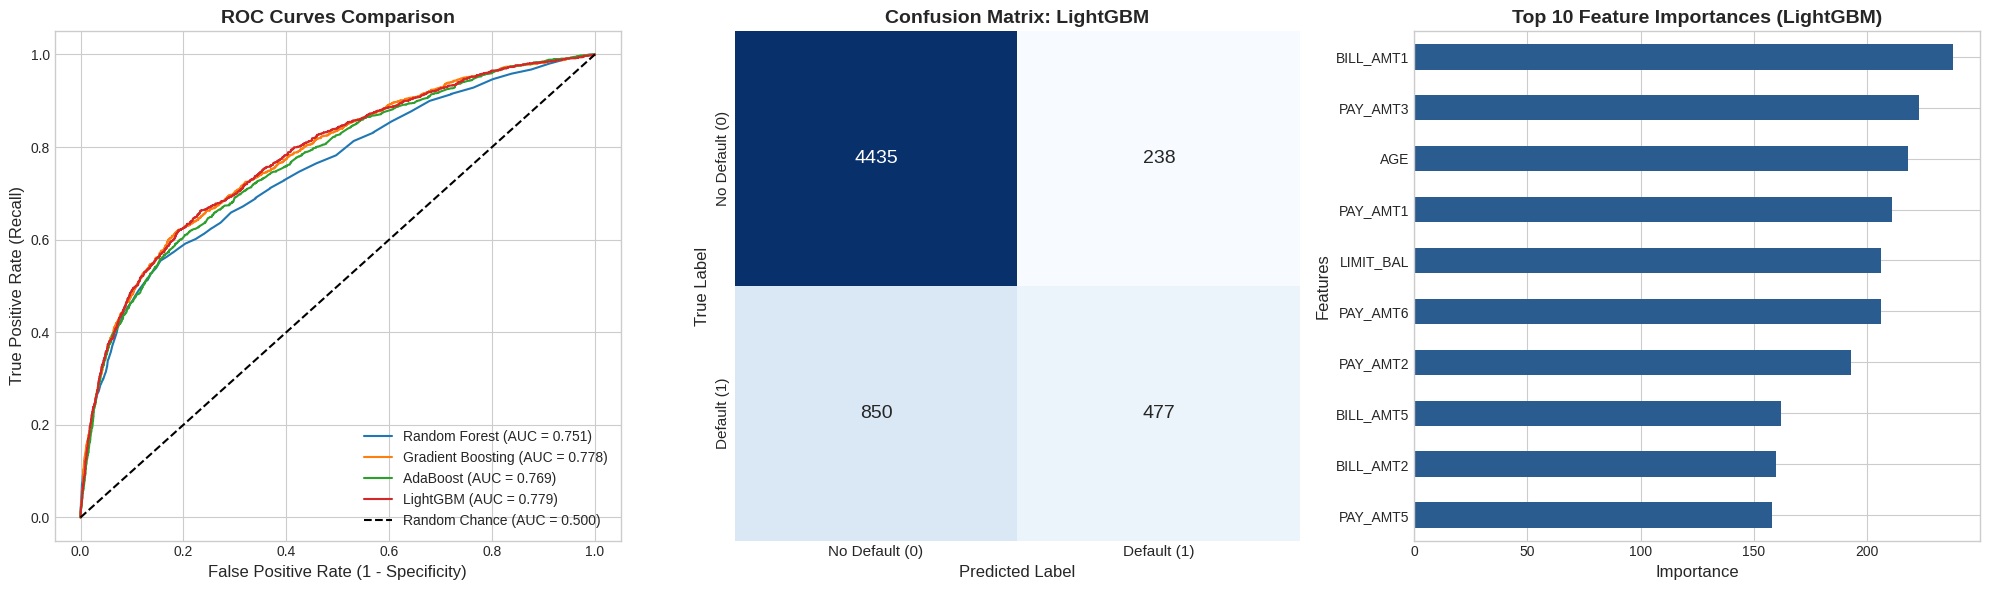

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, confusion_matrix, ConfusionMatrixDisplay

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. ROC Curves
for name, model in trained_models.items():
    y_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_val = df_eval.loc[df_eval['Model'] == name, 'ROC-AUC'].values[0]
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', label='Random Chance (AUC = 0.500)')
axes[0].set_title('ROC Curves Comparison', fontsize=14, fontweight='bold')
axes[0].set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
axes[0].set_ylabel('True Positive Rate (Recall)', fontsize=12)
axes[0].legend(loc='lower right', fontsize=10)

# 2. Confusion Matrix of Best Model (LightGBM)
best_model_name = 'LightGBM'
best_model = trained_models[best_model_name]
y_pred_best = best_model.predict(X_test)
cm = confusion_matrix(y_test, y_pred_best)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            cbar=False, annot_kws={'size': 14})
axes[1].set_title(f'Confusion Matrix: {best_model_name}', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted Label', fontsize=12)
axes[1].set_ylabel('True Label', fontsize=12)
axes[1].set_xticklabels(['No Default (0)', 'Default (1)'], fontsize=11)
axes[1].set_yticklabels(['No Default (0)', 'Default (1)'], fontsize=11)

# 3. Feature Importance of Best Model (LightGBM)
feat_imp = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=True).tail(10)
feat_imp.plot(kind='barh', color='#2b5c8f', ax=axes[2])
axes[2].set_title(f'Top 10 Feature Importances ({best_model_name})', fontsize=14, fontweight='bold')
axes[2].set_xlabel('Importance', fontsize=12)
axes[2].set_ylabel('Features', fontsize=12)

plt.tight_layout()
plt.show()

## Summary:

### Q&A
- **어떤 앙상블 모델이 가장 우수한 성능을 보였는가?**
  - **LightGBM**과 **Gradient Boosting**이 가장 우수한 예측 성능을 달성했습니다 (LightGBM: ROC-AUC 0.7791, Accuracy 81.87% / Gradient Boosting: ROC-AUC 0.7785, Accuracy 81.83%). 특히 LightGBM은 0.46초의 빠른 학습 속도로 연산 효율성과 예측 변별력 모두에서 가장 뛰어난 성능을 보였습니다.
- **연체 예측에 가장 중요한 영향을 미치는 핵심 피처는 무엇인가?**
  - 최근 월 청구 금액(`BILL_AMT1`), 최근 상환 금액(`PAY_AMT3`, `PAY_AMT1`), 고객 연령(`AGE`), 신용 한도액(`LIMIT_BAL`)이 모델의 의사결정에서 가장 높은 기여도를 나타냈습니다.

### Data Analysis Key Findings
- **데이터셋 구성 및 클래스 불균형**: 총 30,000건의 고객 데이터 중 정상 상환(0)은 23,364건(77.88%), 연체 발생(1)은 6,636건(22.12%)으로 약 3.5:1의 불균형 비율을 보였습니다.
- **앙상블 모델별 테스트 성능 비교 (6,000건 테스트셋 기준)**:
  - **LightGBM**: Accuracy 0.8187, Precision 0.6671, Recall 0.3595, F1-Score 0.4672, **ROC-AUC 0.7791** (학습 시간: 0.46초)
  - **Gradient Boosting**: Accuracy 0.8183, Precision 0.6634, Recall 0.3625, F1-Score 0.4688, **ROC-AUC 0.7785** (학습 시간: 14.25초)
  - **AdaBoost**: Accuracy 0.8172, Precision 0.6758, Recall 0.3331, F1-Score 0.4462, **ROC-AUC 0.7686** (학습 시간: 5.42초)
  - **Random Forest**: Accuracy 0.8120, Precision 0.6325, Recall 0.3580, F1-Score 0.4572, **ROC-AUC 0.7506** (학습 시간: 3.97초)
- **혼동 행렬 분석 (LightGBM)**: 정상 고객 4,673명 중 4,435명을 정확히 분류(특이도 약 94.9%)했으나, 실제 연체 고객 1,327명 중 477명만을 감지하여 재현율(Recall)은 35.95%로 나타났습니다.

### Insights or Next Steps
- **분류 임계값(Threshold) 튜닝 및 리샘플링**: 연체 리스크 관리 목적상 연체 고객 미탐지(False Negative) 비용이 크므로, 기본 임계값(0.5)을 0.3~0.4 수준으로 낮추거나 SMOTE/클래스 가중치(`scale_pos_weight`)를 적용하여 Recall을 60% 이상으로 개선할 수 있습니다.
- **피처 엔지니어링**: 최근 청구액 대비 상환액 비율(`PAY_AMT / BILL_AMT`), 한도 소진율(`BILL_AMT / LIMIT_BAL`), 과거 연체 개월 수의 누적 지표 등 파생 변수를 추가하여 부스팅 모델의 변별력을 추가 향상시킬 것을 권장합니다.
